Carlos Francisco Montoya Urzua

20 de Marzo de 2026

#**Evaluacion cruazada e hiperparametros**

La validación cruzada es una técnica robusta de evaluación en machine learning que divide los datos en subconjuntos (folds), entrenando el modelo en  partes y probándolo en la restante, rotando este proceso  veces. Esto maximiza el uso de datos, reduce el sobreajuste y proporciona una métrica de rendimiento promedio más confiable ante nuevos datos.

## Puntos Clave de la Validación Cruzada:

### ¿Cómo funciona? (K-Fold):
El conjunto de datos se divide en k pliegues (generalmente 5 o 10). El modelo se entrena  veces, cada vez usando un pliegue distinto para validación y los
restantes para entrenamiento.

###Resultados:
Al final, se obtiene un promedio de las métricas de evaluación, ofreciendo una visión más realista del rendimiento que una simple división entrenamiento/prueba.

###Ventajas:

Menos sobreajuste: Evita que el modelo dependa de una división aleatoria específica.

Aprovechamiento de datos: Todos los datos se utilizan tanto para entrenamiento como para validación.

Robustez: Es ideal para conjuntos de datos pequeños.

###Variaciones Comunes:

K-Fold: División estándar en k partes.

Estratificada (Stratified K-Fold): Mantiene la proporción de clases en cada pliegue, crucial para datos desequilibrados.

Leave-One-Out (LOOCV): Usa una sola observación para prueba y el resto para entrenamiento; es computacionalmente costoso pero preciso.

###Implementación (Scikit-Learn):

Se utiliza comúnmente con la función cross_val_score o KFold en Python para automatizar el ciclo de entrenamiento y evaluación.

La validación cruzada (Cross-Validation) y los hiperparámetros son dos componentes fundamentales en machine learning para crear modelos precisos y robustos que funcionen correctamente con datos nuevos.

# ¿Qué son los Hiperparámetros?

Son las configuraciones externas que estableces antes de comenzar el entrenamiento de un modelo para controlar su comportamiento y complejidad.

Diferencia Clave: A diferencia de los parámetros (como los pesos o coeficientes, que el modelo aprende solo), los hiperparámetros los define el ingeniero de ML.

Ejemplos Comunes:

Tasa de aprendizaje (Learning rate): Qué tan rápido aprende el modelo.

Profundidad del árbol (Max depth): En árboles de decisión.

Número de árboles (n_estimators): En Random Forest.

Tipo de núcleo (Kernel): En Support Vector Machines (SVM).

Ajuste de Hiperparámetros (Tuning):

El proceso de probar diferentes combinaciones de estos valores para maximizar el rendimiento.

La validación cruzada suele utilizarse dentro del ajuste de hiperparámetros para encontrar la mejor configuración sin "contaminar" los datos de prueba finales.





1. Importar librerías

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

2. Cargar datos

In [2]:
data = load_iris()
X = data.data
y = data.target

3. Definir el modelo

In [3]:
model = DecisionTreeClassifier()

4. Definir hiperparámetros a probar

In [4]:
param_grid = {
    'max_depth': [2, 3, 5, 10],
    'min_samples_split': [2, 5, 10]#minimo de divisiones para hacer el entrenamiento cruzado
}

5. Aplicar Grid Search con Cross-validation

In [16]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,                # 5-fold cross-validation
    scoring='accuracy'
)

grid_search.fit(X, y)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'max_depth': [2, 3, 5, 10],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

6. Ver resultados

In [17]:
print("Mejores parámetros:", grid_search.best_params_)
print("Mejor score:", grid_search.best_score_)

Mejores parámetros: {'max_depth': 3, 'min_samples_split': 2}
Mejor score: 0.9733333333333334


Varianza

Visualizacion

Convertir resultados en tabla

In [18]:
import pandas as pd

results = pd.DataFrame(grid_search.cv_results_)
print(results[['params', 'mean_test_score', 'std_test_score']])

                                        params  mean_test_score  \
0     {'max_depth': 2, 'min_samples_split': 2}         0.933333   
1     {'max_depth': 2, 'min_samples_split': 5}         0.933333   
2    {'max_depth': 2, 'min_samples_split': 10}         0.933333   
3     {'max_depth': 3, 'min_samples_split': 2}         0.973333   
4     {'max_depth': 3, 'min_samples_split': 5}         0.960000   
5    {'max_depth': 3, 'min_samples_split': 10}         0.973333   
6     {'max_depth': 5, 'min_samples_split': 2}         0.966667   
7     {'max_depth': 5, 'min_samples_split': 5}         0.966667   
8    {'max_depth': 5, 'min_samples_split': 10}         0.966667   
9    {'max_depth': 10, 'min_samples_split': 2}         0.960000   
10   {'max_depth': 10, 'min_samples_split': 5}         0.966667   
11  {'max_depth': 10, 'min_samples_split': 10}         0.966667   

    std_test_score  
0         0.047140  
1         0.047140  
2         0.047140  
3         0.024944  
4         0.024944  
5 

In [19]:
results['std_test_score']

,std_test_score
0,0.047140
1,0.047140
2,0.047140
3,0.024944
4,0.024944
5,0.024944
6,0.036515
7,0.021082
8,0.021082
9,0.032660


Graficar resultados

Caso 1: efecto de un hiperparámetro

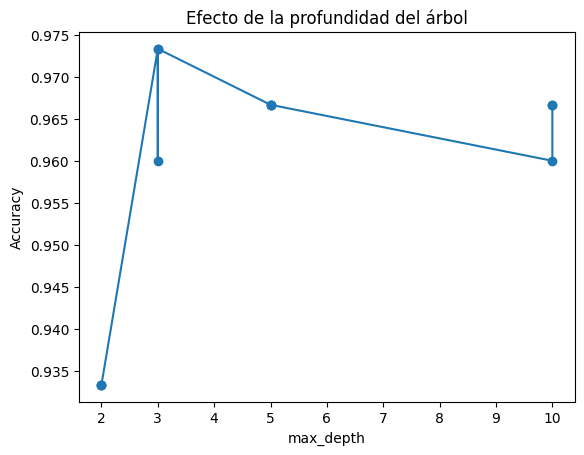

In [20]:
import matplotlib.pyplot as plt

depths = results['param_max_depth']
scores = results['mean_test_score']

plt.figure()
plt.plot(depths, scores, marker='o')
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Efecto de la profundidad del árbol")
plt.show()

Visualización tipo heatmap

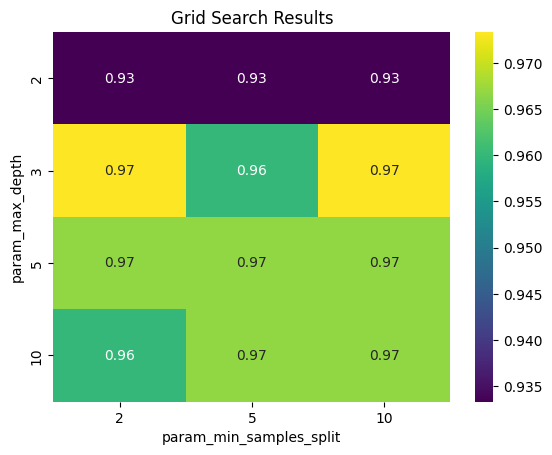

In [21]:
import seaborn as sns

pivot = results.pivot(
    index='param_max_depth',
    columns='param_min_samples_split',
    values='mean_test_score'
)

sns.heatmap(pivot, annot=True, cmap="viridis")
plt.title("Grid Search Results")
plt.show()

Otra version, es para si tenemos muchos datos

In [22]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    model,
    param_distributions=param_grid,
    n_iter=5,
    cv=5,
    scoring='accuracy'
)

random_search.fit(X, y)

RandomizedSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_iter=5,
                   param_distributions={'max_depth': [2, 3, 5, 10],
                                        'min_samples_split': [2, 5, 10]},
                   scoring='accuracy')